In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm, beta
import matplotlib.patches as patches
from numpy.random import default_rng
rng = default_rng()
%matplotlib inline

# introduction to Doolittle-Kraemer skill diagrams

Doolittle-Kraemer skill diagrams use a two-dimensional space of chance-corrected skill scores, the "POD-skill" ($POD_{skill}$, y-axis) and "SR-skill" ($SR_{skill}$, x-axis), for visualizing forecast performance. The skill scores measure how far a forecast's $POD$ and $SR$ are from their values for a random (no-skill) forecast, relative to the distance between random and perfect. They were first derived by Doolittle (1885), who multiplied them together to form his "inference-ratio" (the square of the correlation coefficient for binary data), and the rescaled ROC diagram was introduced in medical research by Kraemer (1988), who called it the "quality ROC".

A Doolittle-Kraemer diagram is a re-scaled version of a performance diagram (Roebber 2009; see intro_performance_diagram.ipynb), and since the POFD-based skill score is equal to the SR-based skill score, it is also a re-scaled version of a ROC diagram (see intro_ROC_diagram.ipynb). After rescaling, every point on the diagram has the same reference forecast (random chance) at the origin and a perfect forecast at the upper-right corner $(1,1)$, so skill can be read directly from the position of a point, even when points come from forecasts of events with different base rates.

In this notebook, we introduce the Doolittle-Kraemer diagram, compare it with performance and ROC diagrams for the same forecasts, show how to display any other score from the 2x2 contingency table in the background, and show how information about potential forecast value can be added to the axes.

## 2x2 contingency table

Forecasts for a well-defined observed event can be evaluated by analyzing the elements of a 2x2 contingency table (see intro_2x2_table.ipynb for more details). A generic form of the 2x2 contingency table is shown below. The elements of the contingency table are the relative frequencies or proportions of each contingency (joint probabilities): $a$ = hits, $b$ = false alarms, $c$ = missed events, $d$ = correct nulls. The base rate is $\bar x = a+c$ and the mean forecast is $\bar f = a+b$.

In [2]:
# generic 2x2 contingency table
pd.DataFrame(data=np.array([['a','b','a+b'],['c','d','c+d'],['a+c','b+d','1']]),index=['fcst=yes','fcst=no','col sum'],columns=['obs=yes','obs=no','row sum'])

,obs=yes,obs=no,row sum
fcst=yes,a,b,a+b
fcst=no,c,d,c+d
col sum,a+c,b+d,1


## chance-corrected skill scores

For a random forecast (forecasts statistically independent of observations), the expected 2x2 table is the product of the marginal probabilities, $a_{random}=(a+b)(a+c)$, so that $POD_{random}=\bar f$ and $SR_{random}=\bar x$ (intro_2x2_table.ipynb). Perfect forecasts have $POD=SR=1$. Rescaling $POD$ and $SR$ so that random = 0 and perfect = 1 gives the two skill scores (Doolittle 1885; Schaefer 1990 called these "skill corrected POD and SR"):

$POD_{skill}=\frac{POD-POD_{random}}{1-POD_{random}}=\frac{ad-bc}{(a+c)(c+d)}$

$SR_{skill}=\frac{SR-SR_{random}}{1-SR_{random}}=\frac{ad-bc}{(a+b)(b+d)}$

The same approach applied to the "no" elements of the table gives two more skill scores, based on the probability of false detection ($POFD=\frac{b}{b+d}$, perfect = 0, random = $\bar f$) and the miss ratio ($MR=\frac{c}{c+d}$, perfect = 0, random = $\bar x$). These turn out to be identical to the first two:

$POFD_{skill}=\frac{POFD-POFD_{random}}{0-POFD_{random}}=SR_{skill}$

$MR_{skill}=\frac{MR-MR_{random}}{0-MR_{random}}=POD_{skill}$

The code below checks these identities numerically for a large set of random 2x2 tables.

In [3]:
# skill score functions
def podskill(a,b,c,d):
    return (a*d-b*c)/(a+c)/(c+d)

def srskill(a,b,c,d):
    return (a*d-b*c)/(a+b)/(b+d)

# numerical check of the identities using random 2x2 tables
tables=rng.dirichlet([1.,1.,1.,1.],size=100000)
a,b,c,d=tables.T
xb=a+c
fb=a+b
pod_s=(a/(a+c)-fb)/(1.-fb)
sr_s=(a/(a+b)-xb)/(1.-xb)
pofd_s=(b/(b+d)-fb)/(0.-fb)
mr_s=(c/(c+d)-xb)/(0.-xb)
print('POD-skill matches (ad-bc)/((a+c)(c+d)):',np.allclose(pod_s,podskill(a,b,c,d)))
print('SR-skill matches (ad-bc)/((a+b)(b+d)):',np.allclose(sr_s,srskill(a,b,c,d)))
print('POFD-skill equals SR-skill:',np.allclose(pofd_s,sr_s))
print('MR-skill equals POD-skill:',np.allclose(mr_s,pod_s))

POD-skill matches (ad-bc)/((a+c)(c+d)): True
SR-skill matches (ad-bc)/((a+b)(b+d)): True
POFD-skill equals SR-skill: True
MR-skill equals POD-skill: True


## 2x2 contingency table in Doolittle-Kraemer $(SR_{skill},POD_{skill})$ space

As with performance and ROC diagrams, the elements of the 2x2 table can be written in terms of the two axes of the diagram and the base rate, which lets us compute any score in the background of the diagram. The ratio of the two skill scores is an odds ratio (the odds of a "yes" forecast divided by the odds of an observed event, which we call "bias-odds"):

$\frac{POD_{skill}}{SR_{skill}}=\frac{\bar f/(1-\bar f)}{\bar x/(1-\bar x)}$

so the mean forecast can be found from the position on the diagram and the base rate:

$\bar f=\frac{POD_{skill}/SR_{skill}}{(1-\bar x)/\bar x+POD_{skill}/SR_{skill}}$

and the table elements are:

In [4]:
# generic 2x2 contingency table in terms of POD-skill, SR-skill, and base rate (fbar defined above)
pd.DataFrame(data=np.array([[r'$\bar x(1-\bar f)POD_{skill}+\bar f\bar x$',r'$\bar f(1-\bar x)(1-SR_{skill})$',r'$\bar f$'],[r'$\bar x(1-\bar f)(1-POD_{skill})$',r'$(1-\bar x)(1-\bar f)+\bar f(1-\bar x)SR_{skill}$',r'$1-\bar f$'],[r'$\bar x$',r'$1-\bar x$','1']]),index=['fcst=yes','fcst=no','col sum'],columns=['obs=yes','obs=no','row sum'])

,obs=yes,obs=no,row sum
fcst=yes,$\bar x(1-\bar f)POD_{skill}+\bar f\bar x$,$\bar f(1-\bar x)(1-SR_{skill})$,$\bar f$
fcst=no,$\bar x(1-\bar f)(1-POD_{skill})$,$(1-\bar x)(1-\bar f)+\bar f(1-\bar x)SR_{skill}$,$1-\bar f$
col sum,$\bar x$,$1-\bar x$,1


In [5]:
# function returning 2x2 table elements from (SR-skill, POD-skill) and base rate
def table_from_skill(sr_s,pod_s,xbar):
    ratio=pod_s/sr_s
    fbar=ratio/((1.-xbar)/xbar+ratio)
    a=xbar*(1.-fbar)*pod_s+fbar*xbar
    b=fbar*(1.-xbar)*(1.-sr_s)
    c=xbar*(1.-fbar)*(1.-pod_s)
    d=(1.-xbar)*(1.-fbar)+fbar*(1.-xbar)*sr_s
    return a,b,c,d

# round-trip check: random tables with positive skill -> (SR-skill, POD-skill, xbar) -> table
pos=(a*d-b*c)>0
a2,b2,c2,d2=table_from_skill(srskill(a,b,c,d)[pos],podskill(a,b,c,d)[pos],(a+c)[pos])
print('table recovered from (SR-skill, POD-skill, base rate):',
      np.allclose(a2,a[pos]) and np.allclose(b2,b[pos]) and np.allclose(c2,c[pos]) and np.allclose(d2,d[pos]))

table recovered from (SR-skill, POD-skill, base rate): True


## generate synthetic forecasts and observations

The code blocks below use the same functions and settings as intro_performance_diagram.ipynb to generate synthetic forecasts and observations (beta-distributed forecasts, following generate_synth_data.ipynb), then compute the 2x2 contingency table across a range of forecast thresholds.

In [6]:
# functions to generate synthetic forecasts and observations and compute the 2x2 contingency table

def synth_data(nn,xbar,fbar,sharp,rhoxf):
    # generate synthetic binary obs with base rate = xbar
    # generate synthetic forecasts [continuous beta-distributed probability-like]
    # generate synthetic forecasts [binary with mean forecast = fbar]
    # rhoxf controls the correlation of the bivariate normal that is used to generate obs and fcst-beta
    # sharp controls the normalized sharpness in determining the beta distribution parameters of the fcsts
    cov = np.array([[1.,rhoxf ], [rhoxf,1.]])
    pts = rng.multivariate_normal([0., 0.], cov, size=nn)
    obs_bin=np.zeros_like(pts[:,0])
    xthresh=norm.ppf(1-xbar,0.,1.)
    obs_bin[pts[:,0]>=xthresh]=1.
    sx21=xbar*(1.-xbar)
    sf21=sharp*sx21
    nu1=fbar*(1-fbar)/sf21-1.
    alpha1=fbar*nu1
    beta1=(1.-fbar)*nu1
    fcst_beta=beta.ppf(norm.cdf(pts[:,1],0.,1.), alpha1,beta1)
    fthresh=np.quantile(fcst_beta,1.-fbar)
    fcst_bin=fcst_beta>=fthresh
    return obs_bin,fcst_beta,fcst_bin

def calc_2x2_table(fcst,obs,thresholds):
    # assuming fcst and obs are of the same length, fcst are continuous and obs are binary
    # loop over thresholds and find elements of 2x2 contingency table for each
    # return these in a pandas dataframe
    nthresh=len(thresholds)
    aa=np.full(nthresh,np.nan)
    bb=np.full(nthresh,np.nan)
    cc=np.full(nthresh,np.nan)
    dd=np.full(nthresh,np.nan)
    for j in np.arange(nthresh):
        fthresh=thresholds[j]
        fcst_bin=fcst>=fthresh
        nn=float(len(obs))
        aa[j]=np.sum(obs*fcst_bin)/nn
        bb[j]=np.sum((1.-obs)*fcst_bin)/nn
        cc[j]=np.sum(obs*(1.-fcst_bin))/nn
        dd[j]=np.sum((1.-obs)*(1.-fcst_bin))/nn
    df=pd.DataFrame(data=np.array([thresholds,aa,bb,cc,dd]).T,columns=['thresh','a','b','c','d'])
    return df

In [7]:
# same settings as intro_performance_diagram.ipynb
nn=100000
xbar=0.05
fbar=0.05
rhoxf=0.8
ratio=0.7

obs_pts,fcst_pts,fcst_bin=synth_data(nn,xbar,fbar,ratio,rhoxf)

# thresholds going from zero to slightly above the max forecast value (POD and POFD go from 1 to 0)
threshs=np.quantile(fcst_pts,np.linspace(0.001,0.999,99))
threshs=np.insert(threshs,0,0.)
threshs=np.append(threshs,np.max(fcst_pts)*1.01)

df = calc_2x2_table(fcst_pts,obs_pts,threshs)
df['POD']=df.a/(df.a+df.c)
df['SR']=df.a/(df.a+df.b)
df['POFD']=df.b/(df.b+df.d)
df['PODskill']=podskill(df.a,df.b,df.c,df.d)
df['SRskill']=srskill(df.a,df.b,df.c,df.d)
df

,thresh,a,b,c,d,POD,SR,POFD,PODskill,SRskill
0,0.000000e+00,0.04962,0.95038,0.00000,0.00000,1.000000,0.049620,1.000000,NaN,0.000000
1,6.828121e-141,0.04962,0.94938,0.00000,0.00100,1.000000,0.049670,0.998948,1.000000,0.000052
2,6.959826e-91,0.04962,0.93919,0.00000,0.01119,1.000000,0.050182,0.988226,1.000000,0.000591
3,5.637459e-78,0.04962,0.92901,0.00000,0.02137,1.000000,0.050704,0.977514,1.000000,0.001140
4,3.009219e-70,0.04962,0.91882,0.00000,0.03156,1.000000,0.051237,0.966792,1.000000,0.001701
...,...,...,...,...,...,...,...,...,...,...
96,7.323540e-01,0.01810,0.01346,0.03152,0.93692,0.364772,0.573511,0.014163,0.344071,0.551243
97,8.823761e-01,0.01394,0.00743,0.03568,0.94295,0.280935,0.652316,0.007818,0.265233,0.634164
98,9.737394e-01,0.00840,0.00279,0.04122,0.94759,0.169287,0.750670,0.002936,0.159886,0.737653
99,9.999243e-01,0.00096,0.00004,0.04866,0.95034,0.019347,0.960000,0.000042,0.018365,0.957912


## the same forecasts on ROC, performance, and Doolittle-Kraemer diagrams

Given a set of observations and paired forecast values, a curve is produced by systematically varying the forecast threshold. Below, the same synthetic forecasts are plotted on all three diagrams, with one threshold highlighted (star).

On the ROC diagram, the curve runs from $(0,0)$ ("all no") to $(1,1)$ ("all yes"). On the performance diagram, it runs from $SR=\bar x, POD=1$ ("all yes") toward the $POD=0$ axis. On the Doolittle-Kraemer diagram, it runs from the upper-left corner toward the lower-right corner: as the forecast approaches "all yes", there are almost no missed events, so $POD_{skill}\rightarrow POD\rightarrow 1$ while $SR_{skill}\rightarrow 0$; as it approaches "all no", there are almost no false alarms, so $SR_{skill}\rightarrow 1$ while $POD_{skill}\rightarrow 0$. (A constant forecast itself has an empty row in the 2x2 table, so the skill scores are undefined at the exact endpoints, and those points are missing from the plot.) Since the random reference is at the origin for every threshold, the distance of each point from the origin, relative to the corner $(1,1)$, shows how much skill the forecast has at that threshold.

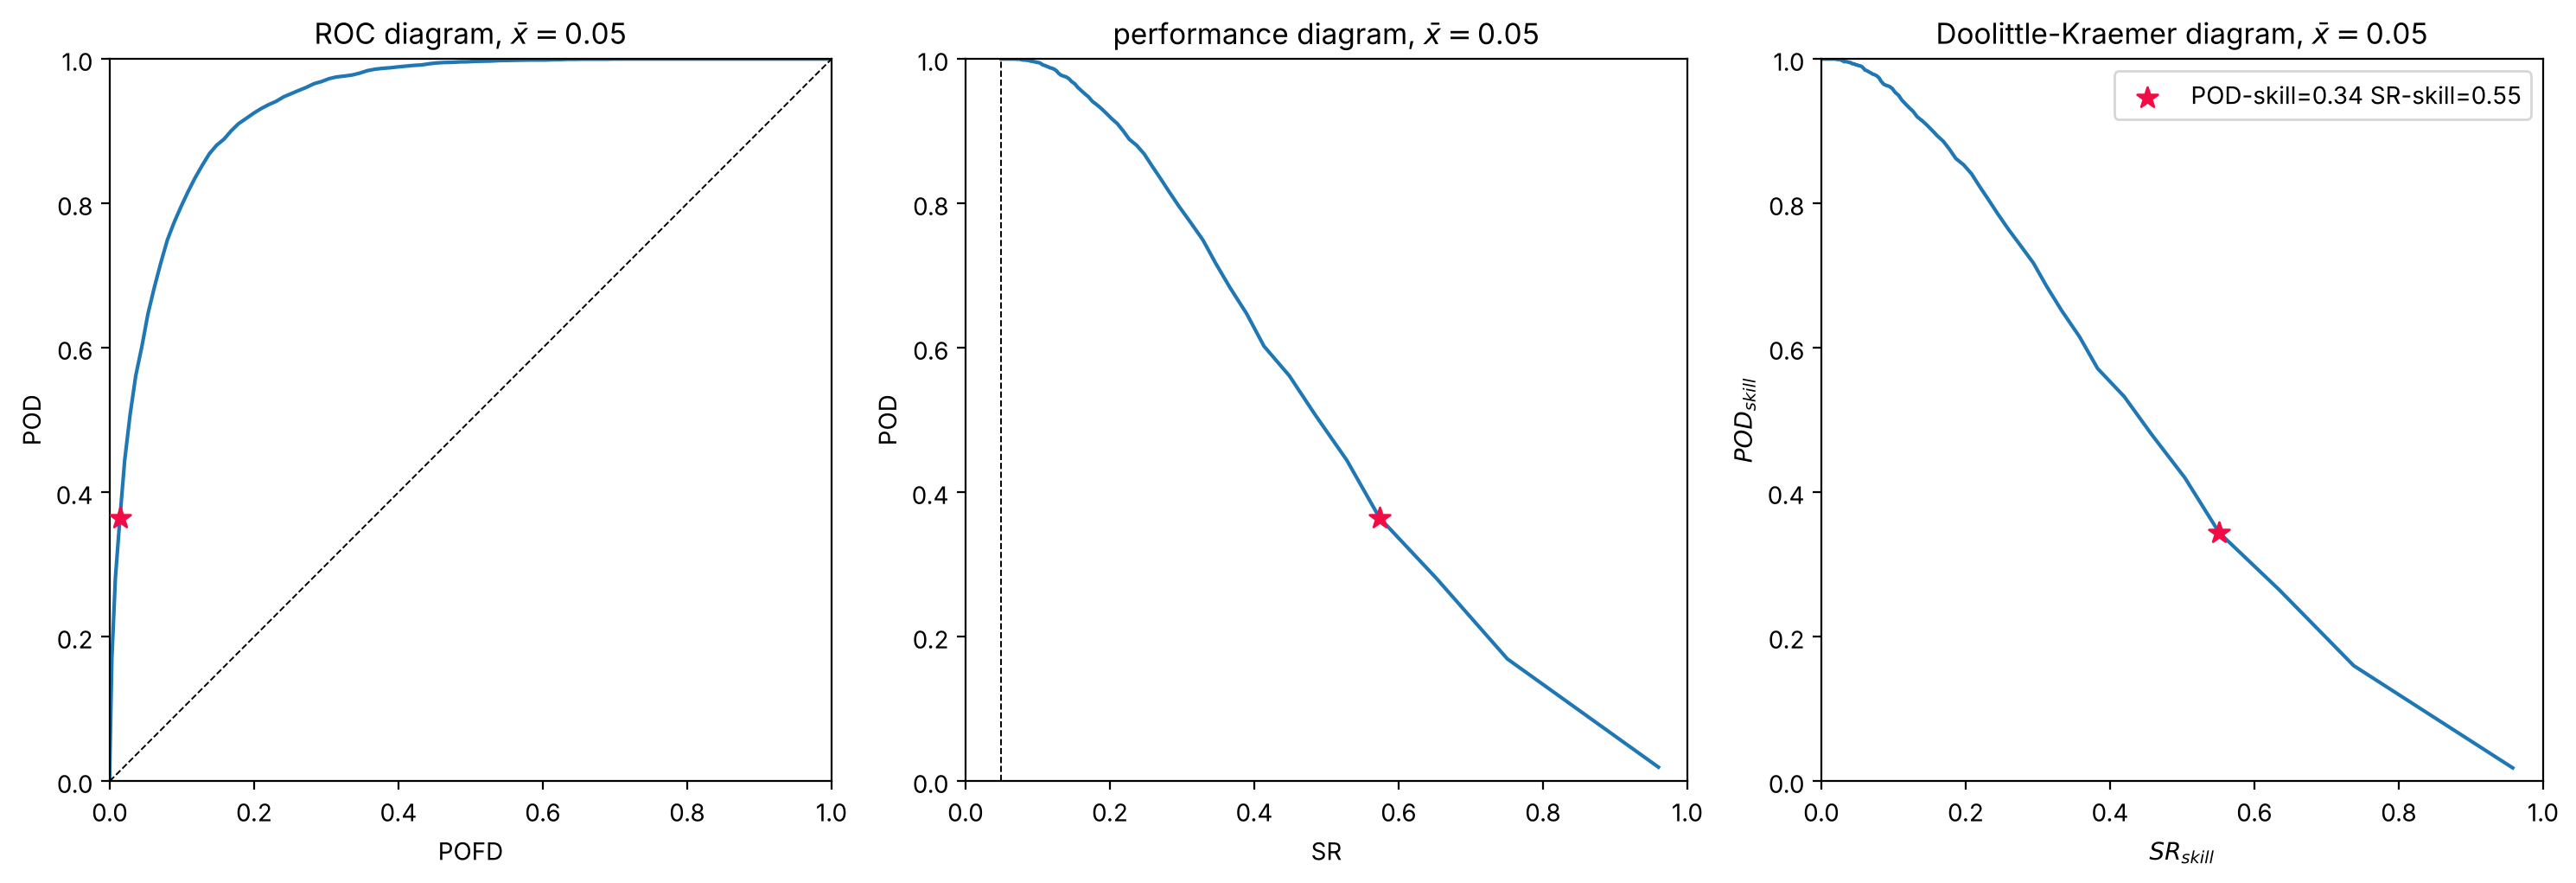

In [8]:
# compare ROC, performance, and Doolittle-Kraemer diagrams for the same forecasts

xbar1=np.mean(obs_pts)
ipt=np.argmax(df.POD<0.4)   # highlighted threshold: first threshold with POD < 0.4

fig,axs = plt.subplots(1,3,figsize=(15,5))

axs[0].plot(df.POFD,df.POD)
axs[0].plot([0,1],[0,1],'k--',lw=0.7)
axs[0].scatter(df.POFD[ipt],df.POD[ipt],marker='*',s=80,color='#f10c45',zorder=3)
axs[0].set_xlabel('POFD')
axs[0].set_ylabel('POD')
axs[0].set_title('ROC diagram')

axs[1].plot(df.SR,df.POD)
axs[1].plot([xbar1,xbar1],[0,1],'k--',lw=0.7)
axs[1].scatter(df.SR[ipt],df.POD[ipt],marker='*',s=80,color='#f10c45',zorder=3)
axs[1].set_xlabel('SR')
axs[1].set_ylabel('POD')
axs[1].set_title('performance diagram')

axs[2].plot(df.SRskill,df.PODskill)
axs[2].scatter(df.SRskill[ipt],df.PODskill[ipt],marker='*',s=80,color='#f10c45',zorder=3,
               label=f'POD-skill={np.round(df.PODskill[ipt],2)} SR-skill={np.round(df.SRskill[ipt],2)}')
axs[2].set_xlabel(r'$SR_{skill}$')
axs[2].set_ylabel(r'$POD_{skill}$')
axs[2].set_title('Doolittle-Kraemer diagram')
axs[2].legend()

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xlim(0.,1.)
    ax.set_ylim(0.,1.)
for ax,name in zip(axs,['ROC diagram','performance diagram','Doolittle-Kraemer diagram']):
    ax.set_title(name+r', $\bar x =$'+f'{np.round(xbar1,3)}')
plt.tight_layout()

## "no skill" reference

On a performance diagram, a random forecast follows the vertical line $SR=\bar x$; on a ROC diagram it follows the diagonal $POD=POFD$. These lines are often not shown, and their positions change with base rate (performance diagram) or depend on the threshold (both diagrams: every point on the line is a different reference forecast). On a Doolittle-Kraemer diagram, the random reference forecast for *every* threshold and *every* base rate is the origin.

As in intro_performance_diagram.ipynb, the array of synthetic forecasts is randomly permuted below, and the 2x2 tables are recalculated from the same thresholds. The permuted forecasts follow the no-skill lines on the ROC and performance diagrams and collapse toward the origin on the Doolittle-Kraemer diagram. The departures from zero are sampling noise, which is largest at the most extreme thresholds, where only a small number of "yes" (or "no") forecasts are issued; points with negative skill fall outside the plotted unit square.

permuted forecasts, median over thresholds of max(|POD-skill|,|SR-skill|): 0.008
largest value: 0.411 at a threshold with mean forecast 0.999


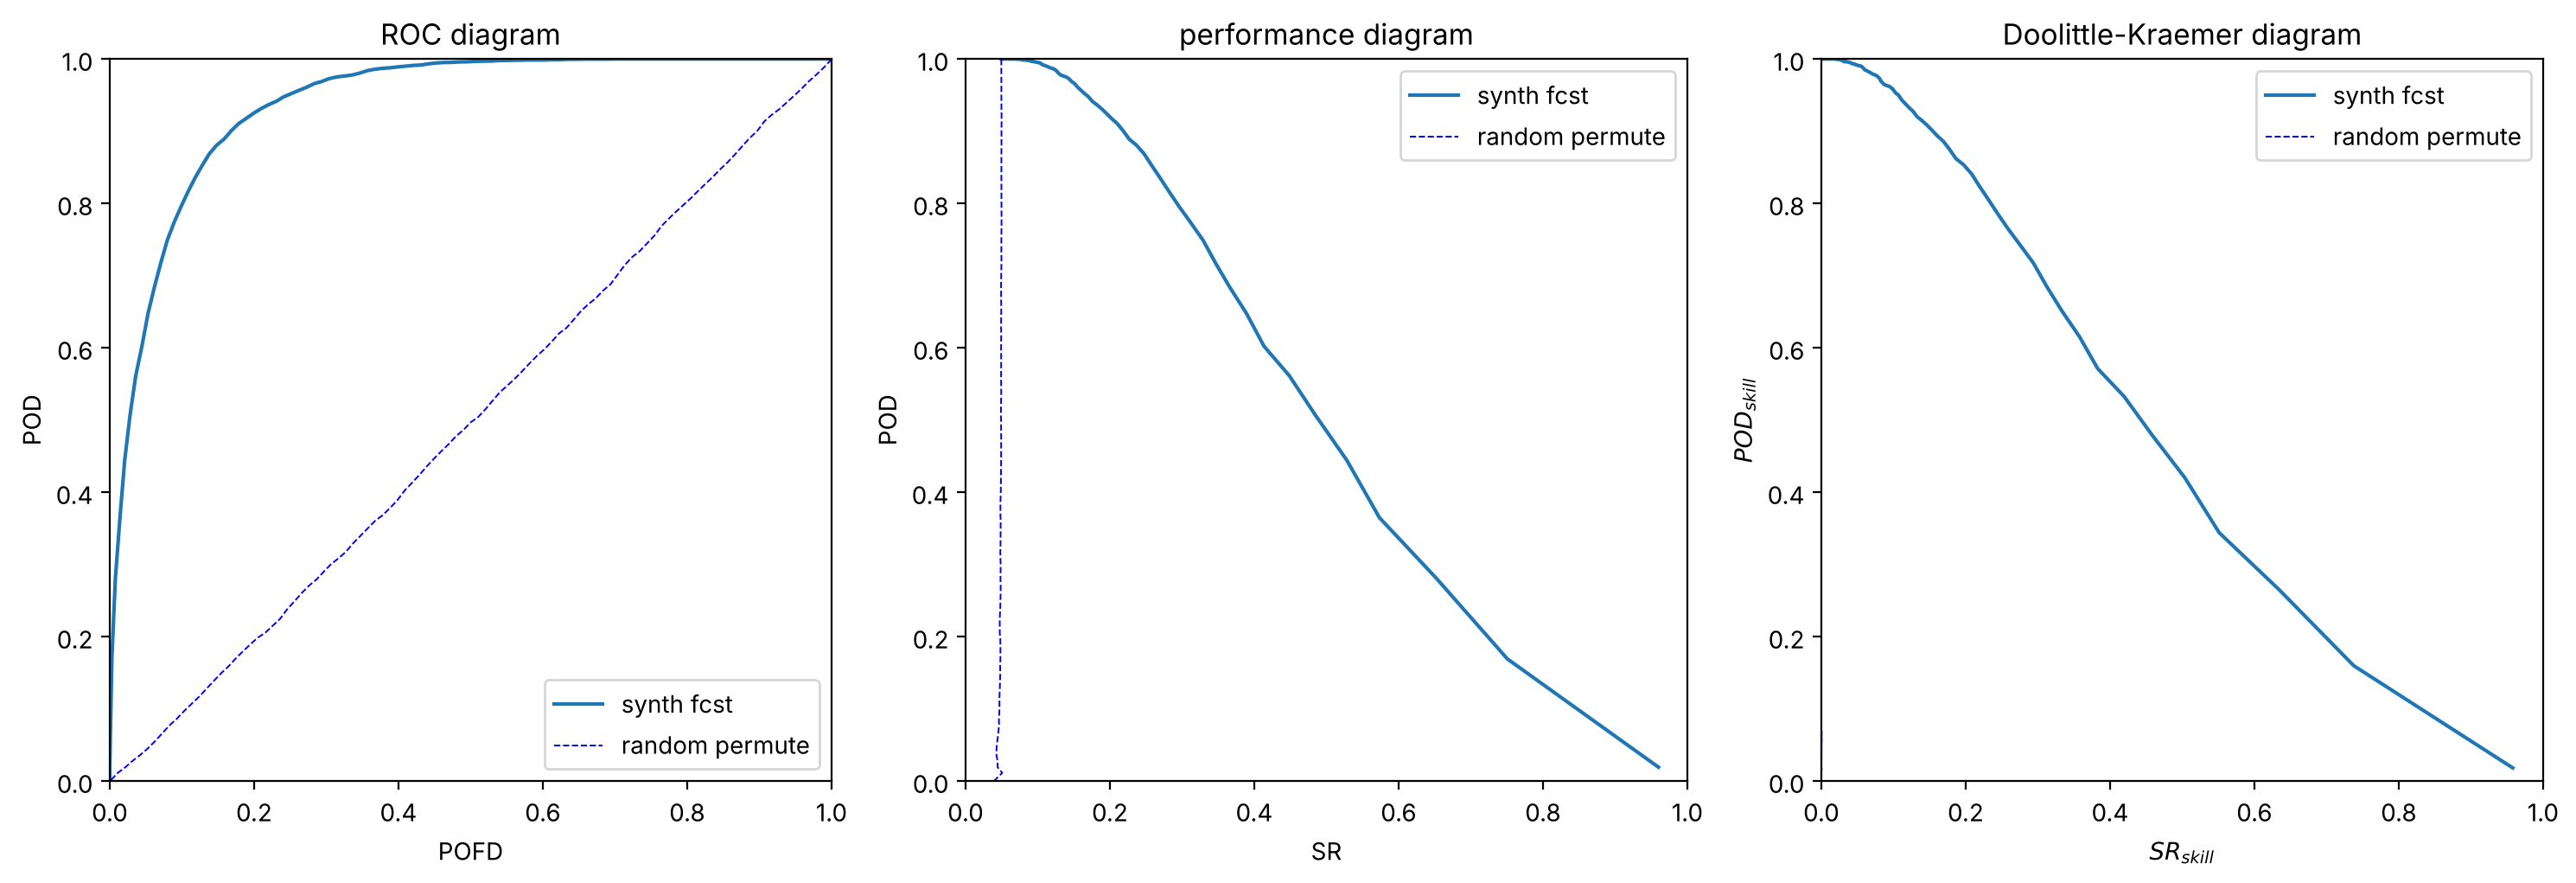

In [9]:
# randomly shuffle the forecast array and generate the corresponding 2x2 contingency table
fcst_rand=rng.permutation(fcst_pts)
df_perm = calc_2x2_table(fcst_rand,obs_pts,threshs)
df_perm['POD']=df_perm.a/(df_perm.a+df_perm.c)
df_perm['SR']=df_perm.a/(df_perm.a+df_perm.b)
df_perm['POFD']=df_perm.b/(df_perm.b+df_perm.d)
df_perm['PODskill']=podskill(df_perm.a,df_perm.b,df_perm.c,df_perm.d)
df_perm['SRskill']=srskill(df_perm.a,df_perm.b,df_perm.c,df_perm.d)

fig,axs = plt.subplots(1,3,figsize=(15,5))
axs[0].plot(df.POFD,df.POD,label='synth fcst')
axs[0].plot(df_perm.POFD,df_perm.POD,'b--',lw=0.7,label='random permute')
axs[0].set_xlabel('POFD'); axs[0].set_ylabel('POD'); axs[0].set_title('ROC diagram')
axs[1].plot(df.SR,df.POD,label='synth fcst')
axs[1].plot(df_perm.SR,df_perm.POD,'b--',lw=0.7,label='random permute')
axs[1].set_xlabel('SR'); axs[1].set_ylabel('POD'); axs[1].set_title('performance diagram')
axs[2].plot(df.SRskill,df.PODskill,label='synth fcst')
axs[2].plot(df_perm.SRskill,df_perm.PODskill,'b--',lw=0.7,label='random permute')
axs[2].set_xlabel(r'$SR_{skill}$'); axs[2].set_ylabel(r'$POD_{skill}$'); axs[2].set_title('Doolittle-Kraemer diagram')
for ax in axs:
    ax.set_aspect('equal'); ax.set_xlim(0.,1.); ax.set_ylim(0.,1.); ax.legend()
plt.tight_layout()

abs_skill=df_perm[['PODskill','SRskill']].abs().max(axis=1)
imax=abs_skill.idxmax()
print('permuted forecasts, median over thresholds of max(|POD-skill|,|SR-skill|):',np.round(abs_skill.median(),3))
print('largest value:',np.round(abs_skill[imax],3),'at a threshold with mean forecast',np.round(df_perm.a[imax]+df_perm.b[imax],4))

## add other scores in the background

Since the 2x2 table can be written in terms of $(SR_{skill},POD_{skill})$ and $\bar x$, any score can be plotted in the background. Two scores have a simple geometric form in this space:

- the geometric mean of the two axes is the correlation coefficient for binary forecasts and observations, also known as Yule's $\phi$ (Yule 1912) and the Matthews correlation coefficient (Matthews 1975): $\sqrt{POD_{skill}\,SR_{skill}}=\frac{ad-bc}{\sqrt{(a+b)(a+c)(b+d)(c+d)}}=\phi$
- the harmonic mean of the two axes is the Heidke skill score (Heidke 1926), also known as Cohen's kappa: $\frac{2}{1/POD_{skill}+1/SR_{skill}}=HSS$

Because these are functions of the axes alone, their contours do not change with base rate. The angle of a point from the x-axis gives the bias-odds, $\tan\theta=POD_{skill}/SR_{skill}$. Points above the main diagonal over-forecast and points below it under-forecast, and the frequency bias, $bias=\frac{\tan\theta}{1+\bar x(\tan\theta-1)}$, is constant along straight lines through the origin. Unlike $\phi$ and $HSS$, the bias lines *do* depend on base rate: for a given bias, the line moves as $\bar x$ changes, and $\theta=90^{\circ}$ corresponds to the largest possible bias, $1/\bar x$.

The code below checks that $\phi$ and $HSS$ computed from the full 2x2 table do not depend on base rate in this space, then plots $\phi$ (color fill) and bias (dashed lines) for two base rates. Each panel shows a synthetic forecast with the matching base rate: the data generated above ($\bar x\approx0.05$) on the left, and a second set generated with `synth_data()` using $\bar x=\bar f=0.33$ and the same correlation and sharpness settings on the right. Many other scores (e.g., $CSI$, which is base-rate-invariant on a performance diagram) do vary with base rate in this space.

In [10]:
# score functions
def phi(a,b,c,d):
    return (a*d-b*c)/np.sqrt((a+c)*(c+d)*(a+b)*(b+d))

def hss(a,b,c,d):
    return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))

def csi(a,b,c,d):
    return a/(a+b+c)

def bias(a,b,c,d):
    return (a+b)/(a+c)

def dprime(a,b,c,d):
    return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))

# arrays hold 2d fields of SR-skill, POD-skill to allow for calculation of scores in background of plots
pods_y=np.arange(0.001,1.0,0.001)
srs_x=np.arange(0.001,1.0,0.001)
srs_2d,pods_2d=np.meshgrid(srs_x,pods_y)

# check: phi and HSS from the full table are the same for different base rates, CSI is not
for xb in [0.01,0.05,0.33,0.75]:
    aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)
    print(f'xbar={xb}: phi = sqrt(PODskill*SRskill)?',np.allclose(phi(aa_2d,bb_2d,cc_2d,dd_2d),np.sqrt(pods_2d*srs_2d)),
          '| HSS = harmonic mean?',np.allclose(hss(aa_2d,bb_2d,cc_2d,dd_2d),2./(1./pods_2d+1./srs_2d)),
          '| CSI at (0.5,0.5) =',np.round(csi(*table_from_skill(0.5,0.5,xb)),3))

xbar=0.01: phi = sqrt(PODskill*SRskill)? True | HSS = harmonic mean? True | CSI at (0.5,0.5) = 0.338
xbar=0.05: phi = sqrt(PODskill*SRskill)? True | HSS = harmonic mean? True | CSI at (0.5,0.5) = 0.356
xbar=0.33: phi = sqrt(PODskill*SRskill)? True | HSS = harmonic mean? True | CSI at (0.5,0.5) = 0.498
xbar=0.75: phi = sqrt(PODskill*SRskill)? True | HSS = harmonic mean? True | CSI at (0.5,0.5) = 0.778


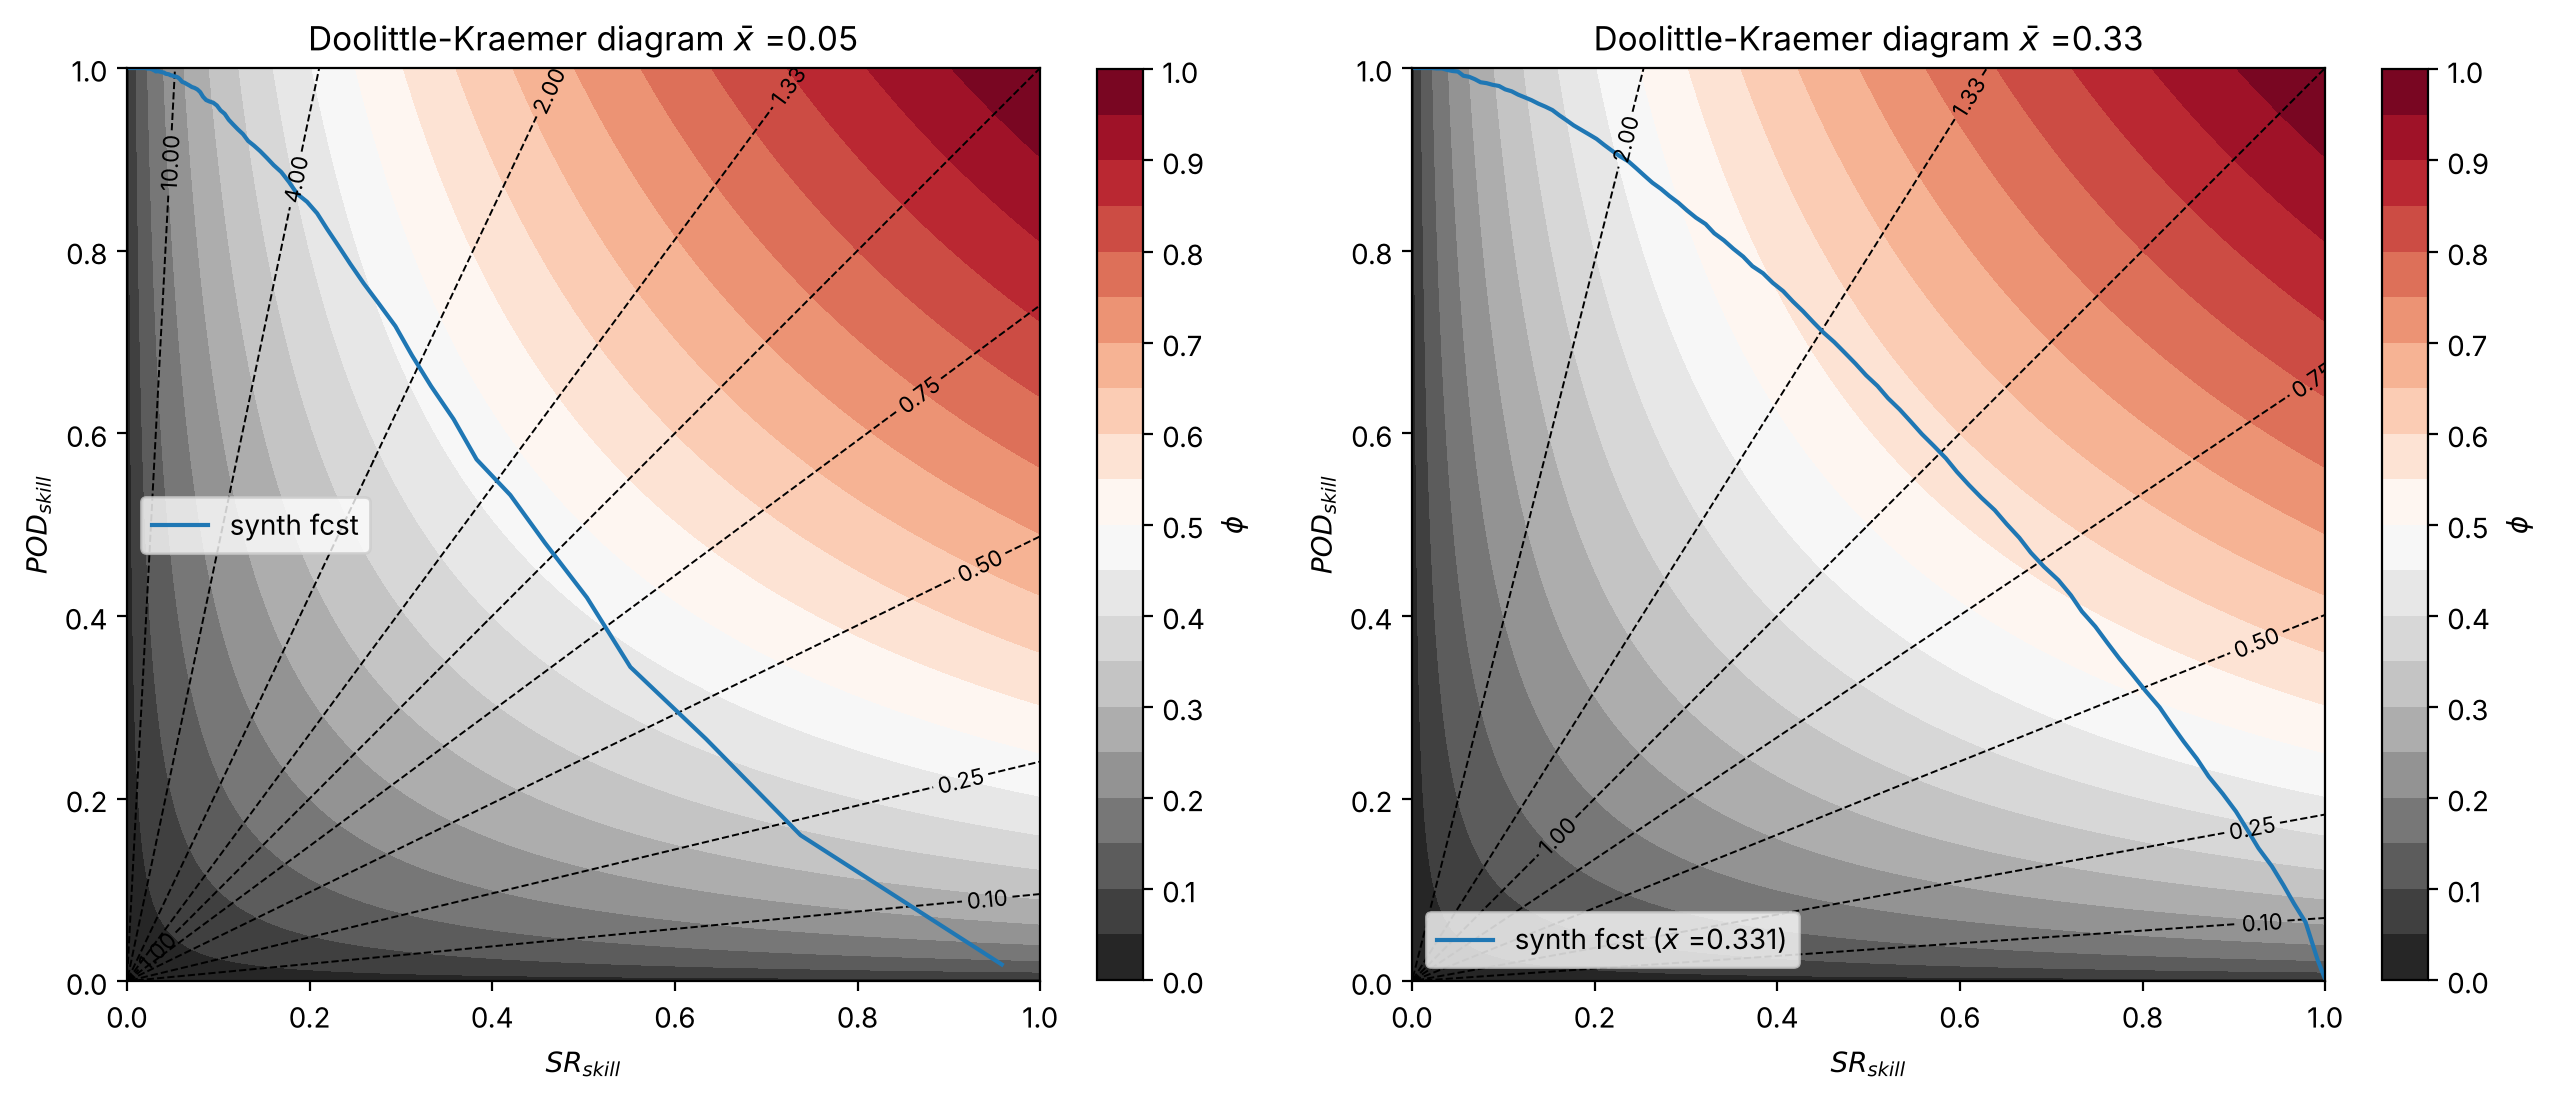

In [11]:
# Doolittle-Kraemer diagram with phi in the background and bias lines, for two base rates

fig, axs = plt.subplots(1,2,figsize=(13,6))

label1=r'$\phi$'
d_lvls=np.linspace(0.,1.,21)
d_ticks=np.linspace(0.,1.,11)

for ax,xb in zip(axs,[0.05,0.33]):
    aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)
    cs0=ax.contour(srs_x,pods_y,bias(aa_2d,bb_2d,cc_2d,dd_2d),levels=np.array([0.1,0.25,0.5,0.75,1.,1.33,2.,4.,10.]),colors='k',linestyles='dashed',linewidths=0.7)
    ax.clabel(cs0, cs0.levels, inline=True, fontsize=8)
    sc1=ax.contourf(srs_x,pods_y,phi(aa_2d,bb_2d,cc_2d,dd_2d),levels=d_lvls,cmap='RdGy_r')
    plt.colorbar(sc1,orientation='vertical',shrink=0.8,label=label1,ax=ax,ticks=d_ticks)
    ax.set_aspect('equal')
    ax.set_xlim(0.,1.)
    ax.set_ylim(0.,1.)
    ax.set_xlabel(r'$SR_{skill}$')
    ax.set_ylabel(r'$POD_{skill}$')
    ax.set_title(r'Doolittle-Kraemer diagram $\bar x$ ='+f'{xb}')

# synthetic forecasts with base rate near 0.05 (generated above) on the left panel
axs[0].plot(df.SRskill,df.PODskill,label='synth fcst')
axs[0].legend()

# second synthetic data set with base rate (and mean forecast) of 0.33, other settings unchanged, on the right panel
obs_33,fcst_33,fcst_bin_33=synth_data(nn,0.33,0.33,ratio,rhoxf)
threshs_33=np.quantile(fcst_33,np.linspace(0.001,0.999,99))
threshs_33=np.insert(threshs_33,0,0.)
threshs_33=np.append(threshs_33,np.max(fcst_33)*1.01)
df_33=calc_2x2_table(fcst_33,obs_33,threshs_33)
df_33['PODskill']=podskill(df_33.a,df_33.b,df_33.c,df_33.d)
df_33['SRskill']=srskill(df_33.a,df_33.b,df_33.c,df_33.d)
axs[1].plot(df_33.SRskill,df_33.PODskill,label=r'synth fcst ($\bar x$ ='+f'{np.round(np.mean(obs_33),3)})')
axs[1].legend()
plt.tight_layout()

## "no skill" and "unachievable" regions

On a performance diagram, the region $SR<\bar x$ has negative skill, and part of it (the "unachievable region" of Boyd et al. 2012) cannot be reached at all; both regions change with base rate and can cover most of the diagram for common events. On a Doolittle-Kraemer diagram, the two skill scores always have the same sign (both have $ad-bc$ in the numerator and positive denominators), so forecasts with positive skill are in the upper-right quadrant, and forecasts worse than random are in the lower-left quadrant (negative values on both axes). Displaying the unit square therefore shows exactly the positive-skill region, for any base rate.

Within the unit square, every point corresponds to a valid 2x2 table (all four elements between 0 and 1) for any base rate, so there is no unachievable region. The code below checks this on a grid for several base rates.

In [12]:
# check that every point in the unit square gives a valid 2x2 table, for a range of base rates
for xb in [0.001,0.01,0.05,0.1,0.33,0.5,0.75,0.95,0.999]:
    aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)
    elems=np.stack([aa_2d,bb_2d,cc_2d,dd_2d])
    print(f'xbar={xb}: min element = {elems.min():.2e}, max element = {elems.max():.4f}, rows/cols sum to 1:',
          np.allclose(aa_2d+bb_2d+cc_2d+dd_2d,1.))

xbar=0.001: min element = 1.00e-09, max element = 0.9990, rows/cols sum to 1: True
xbar=0.01: min element = 1.00e-08, max element = 0.9900, rows/cols sum to 1: True
xbar=0.05: min element = 5.00e-08, max element = 0.9500, rows/cols sum to 1: True
xbar=0.1: min element = 1.00e-07, max element = 0.9000, rows/cols sum to 1: True
xbar=0.33: min element = 3.30e-07, max element = 0.6700, rows/cols sum to 1: True


xbar=0.5: min element = 5.00e-07, max element = 0.5000, rows/cols sum to 1: True
xbar=0.75: min element = 2.50e-07, max element = 0.7500, rows/cols sum to 1: True
xbar=0.95: min element = 5.00e-08, max element = 0.9500, rows/cols sum to 1: True
xbar=0.999: min element = 1.00e-09, max element = 0.9990, rows/cols sum to 1: True


## potential value: utility-ratio axes

For the simple 2x2 decision problem (e.g., Richardson 2000; Wandishin and Brooks 2002), a user who takes protective action when a "yes" forecast is issued compares the forecasts with a uniform reference decision ("always protect" or "never protect"). The user's sensitivity to missed events and false alarms is described by the utility (cost-loss) ratio $\alpha=\frac{cost_{FA}}{cost_{FA}+cost_{ME}}$. The relative value of the forecasts is

$V_{rel}=\frac{(1-\alpha)\bar x(POD)-\alpha(1-\bar x)POFD}{(1-\alpha)\bar x}$ if $\alpha>\bar x$, and $V_{rel}=\frac{\alpha(1-\bar x)(1-POFD)-(1-\alpha)\bar x(1-POD)}{\alpha(1-\bar x)}$ if $\alpha<\bar x$.

Wandishin and Brooks (2002) showed that forecasts have positive value for users with $MR<\alpha<SR$. On a Doolittle-Kraemer diagram these bounds are linear functions of the axes:

$\alpha_{lower}=MR=\bar x(1-POD_{skill})$

$\alpha_{upper}=SR=(1-\bar x)SR_{skill}+\bar x$

so the axes can be relabeled (right and top) to show the range of users who would gain from the forecasts. Users with $\alpha$ close to $\bar x$ (the hardest reference decision) gain from any forecast with positive skill; users with $\alpha$ far below $\bar x$ need high $POD_{skill}$, and users with $\alpha$ far above $\bar x$ need high $SR_{skill}$.

The code below checks numerically that $V_{rel}>0$ exactly where $\alpha_{lower}<\alpha<\alpha_{upper}$ (grid points where $V_{rel}$ is within $10^{-12}$ of zero are skipped, since there the comparison depends only on rounding), then plots $V_{rel}$ for two users with the utility-ratio axes added.

In [13]:
# relative value (vectorized version of relvalue() in intro_performance_diagram.ipynb)
def relvalue(a,b,c,d,alpha,xbar):
    return np.where(alpha>xbar,((1.-alpha)*a-alpha*b)/(1.-alpha)/xbar,(alpha*d-(1.-alpha)*c)/alpha/(1.-xbar))

def mr(a,b,c,d):
    return c/(c+d)

def sr(a,b,c,d):
    return a/(a+b)

# check: Vrel > 0 exactly where MR < alpha < SR
for xb in [0.05,0.33]:
    aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)
    for alpha in [0.2*xb,0.5*xb,2.*xb,min(5.*xb,0.95)]:
        v=relvalue(aa_2d,bb_2d,cc_2d,dd_2d,alpha,xb)
        inside=(mr(aa_2d,bb_2d,cc_2d,dd_2d)<alpha)&(alpha<sr(aa_2d,bb_2d,cc_2d,dd_2d))
        ok=np.abs(v)>1.e-12
        print(f'xbar={xb}, alpha={alpha:.3f}: (Vrel>0) == (MR<alpha<SR) at all grid points:',np.array_equal((v>0)[ok],inside[ok]),
              f'({(~ok).sum()} points on the Vrel=0 line skipped)')

xbar=0.05, alpha=0.010: (Vrel>0) == (MR<alpha<SR) at all grid points: True (999 points on the Vrel=0 line skipped)
xbar=0.05, alpha=0.025: (Vrel>0) == (MR<alpha<SR) at all grid points: True (999 points on the Vrel=0 line skipped)
xbar=0.05, alpha=0.100: (Vrel>0) == (MR<alpha<SR) at all grid points: True (0 points on the Vrel=0 line skipped)
xbar=0.05, alpha=0.250: (Vrel>0) == (MR<alpha<SR) at all grid points: True (0 points on the Vrel=0 line skipped)


xbar=0.33, alpha=0.066: (Vrel>0) == (MR<alpha<SR) at all grid points: True (999 points on the Vrel=0 line skipped)
xbar=0.33, alpha=0.165: (Vrel>0) == (MR<alpha<SR) at all grid points: True (999 points on the Vrel=0 line skipped)
xbar=0.33, alpha=0.660: (Vrel>0) == (MR<alpha<SR) at all grid points: True (0 points on the Vrel=0 line skipped)
xbar=0.33, alpha=0.950: (Vrel>0) == (MR<alpha<SR) at all grid points: True (0 points on the Vrel=0 line skipped)


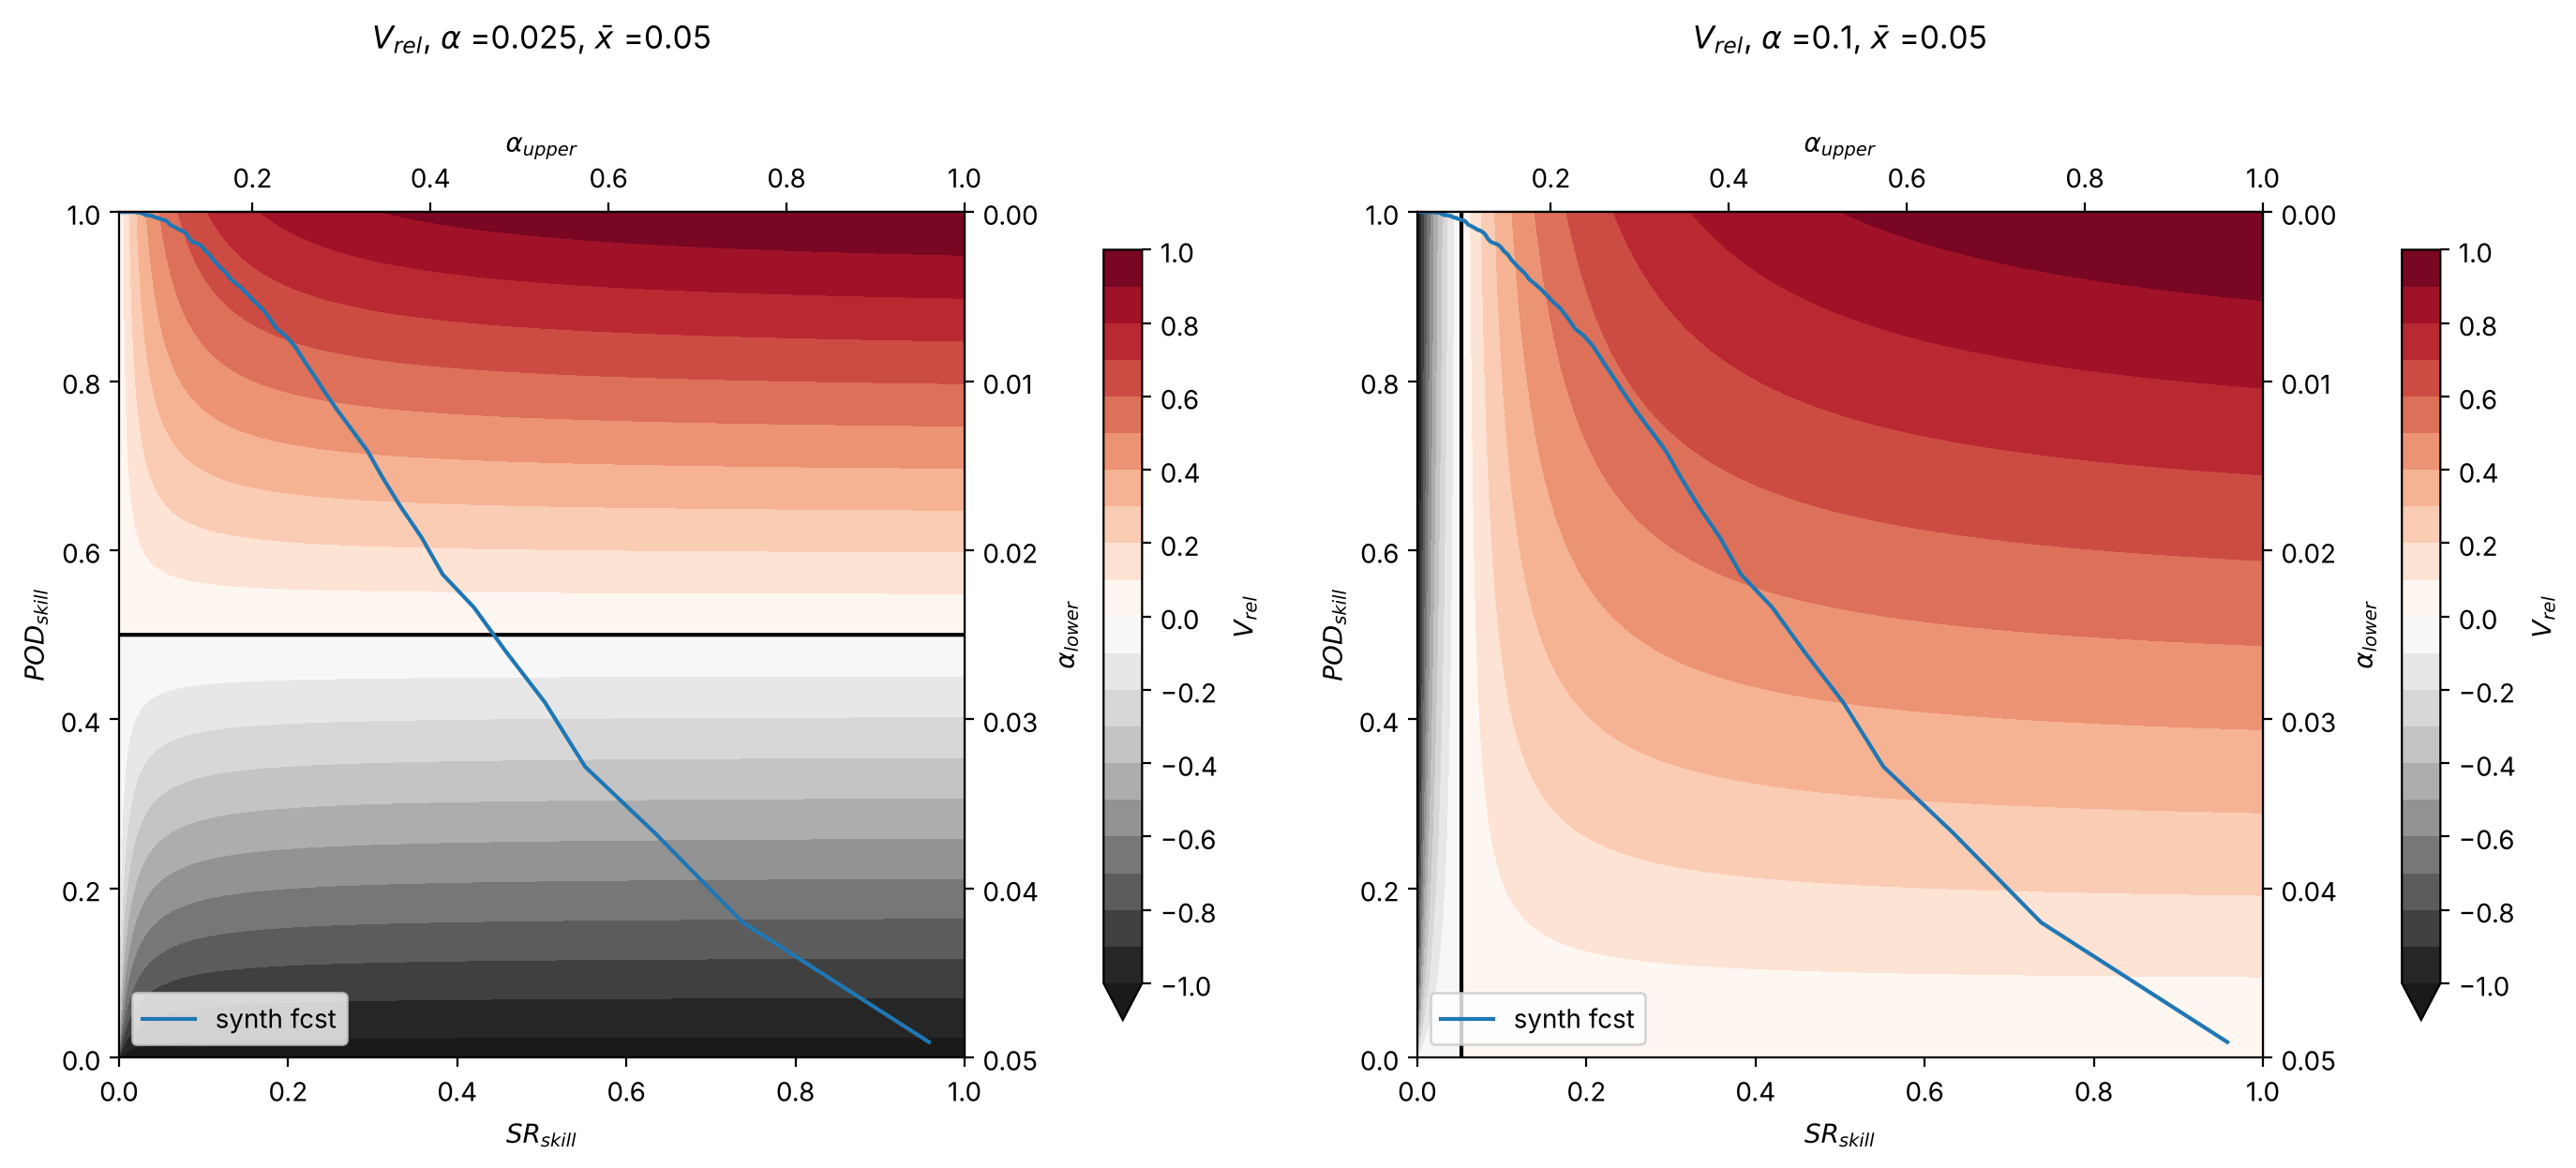

In [14]:
# Doolittle-Kraemer diagram with relative value in the background and utility-ratio axes

xb=0.05

# secondary axis functions for this base rate
def srs2alpha_upper(x):
    return (1.-xb)*x+xb
def alpha_upper2srs(x):
    return (x-xb)/(1.-xb)
def pods2alpha_lower(y):
    return xb*(1.-y)
def alpha_lower2pods(y):
    return 1.-y/xb

aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)

fig, axs = plt.subplots(1,2,figsize=(14,6.5))
d_lvls=np.linspace(-1.,1.,21)
d_ticks=np.linspace(-1.,1.,11)

for ax,alpha in zip(axs,[0.5*xb,2.*xb]):
    v=relvalue(aa_2d,bb_2d,cc_2d,dd_2d,alpha,xb)
    sc1=ax.contourf(srs_x,pods_y,v,levels=d_lvls,cmap='RdGy_r',extend='min')
    ax.contour(srs_x,pods_y,v,levels=[0.],colors='k',linewidths=1.5)
    plt.colorbar(sc1,orientation='vertical',shrink=0.7,pad=0.12,label=r'$V_{rel}$',ax=ax,ticks=d_ticks)
    ax.plot(df.SRskill,df.PODskill,label='synth fcst')
    ax.set_aspect('equal')
    ax.set_xlim(0.,1.)
    ax.set_ylim(0.,1.)
    ax.set_xlabel(r'$SR_{skill}$')
    ax.set_ylabel(r'$POD_{skill}$')
    ax.set_title(r'$V_{rel}$, $\alpha$ ='+f'{np.round(alpha,3)}, '+r'$\bar x$ ='+f'{xb}',pad=30)
    secax = ax.secondary_xaxis('top', functions=(srs2alpha_upper, alpha_upper2srs))
    secay = ax.secondary_yaxis('right', functions=(pods2alpha_lower, alpha_lower2pods))
    secax.set_xlabel(r'$\alpha_{upper}$')
    secay.set_ylabel(r'$\alpha_{lower}$')
    ax.legend(loc='lower left')
plt.tight_layout()

In each panel, the solid black line is $V_{rel}=0$. For the user with $\alpha=0.5\bar x$ (more sensitive to missed events, left), it is the horizontal line where $\alpha_{lower}=\alpha$: points above it have positive value regardless of $SR_{skill}$. For the user with $\alpha=2\bar x$ (more sensitive to false alarms, right), it is the vertical line where $\alpha_{upper}=\alpha$. Following the synthetic forecast curve shows which forecast thresholds would benefit each user.

## sensitivity to base rate

intro_performance_diagram.ipynb shows an example of a very common event ($\bar x=0.75$): an operational NWP model's performance in predicting $CAPE\ge$ 250 J/kg at 00 UTC in the warm season and southern part of the U.S. ($POD=0.88$, $SR=0.94$). On a standard performance diagram the point is near the upper-right corner and looks nearly perfect; once the no-skill region ($SR<0.75$) is shown, it looks less impressive. The code below places the same point on a Doolittle-Kraemer diagram, where its distance from a perfect forecast can be read directly.

mean forecast = 0.702, bias = 0.936
POD-skill = 0.597, SR-skill = 0.760, phi = 0.674


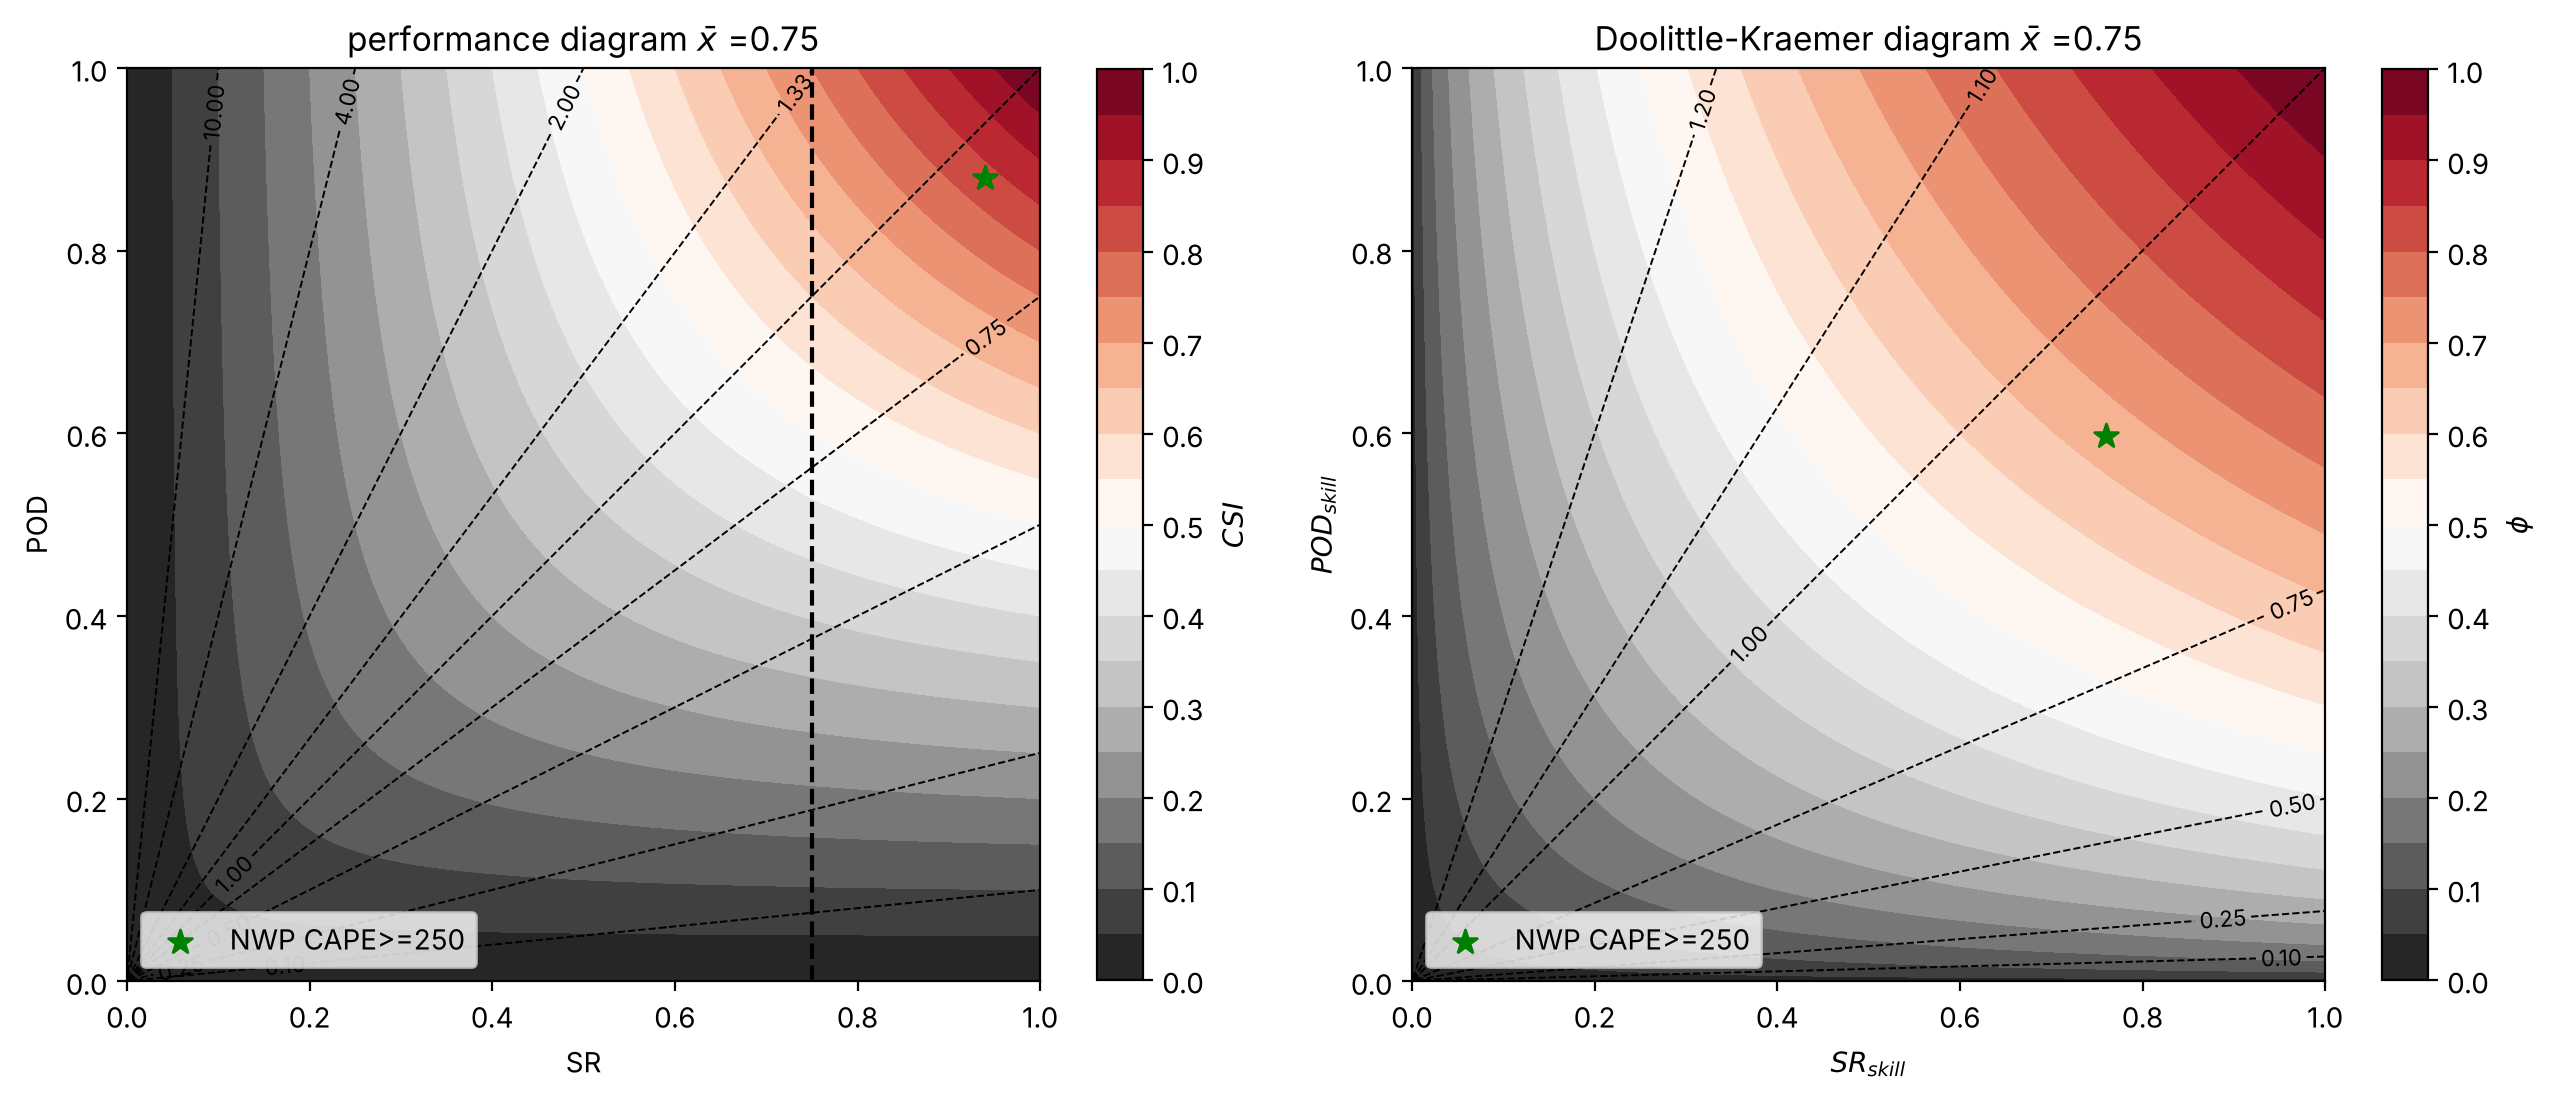

In [15]:
# very common event example from intro_performance_diagram.ipynb
xb=0.75
pod_cape=0.88
sr_cape=0.94

fbar_cape=xb*pod_cape/sr_cape                       # mean forecast from POD, SR, base rate
pods_cape=(pod_cape-fbar_cape)/(1.-fbar_cape)
srs_cape=(sr_cape-xb)/(1.-xb)
print(f'mean forecast = {fbar_cape:.3f}, bias = {pod_cape/sr_cape:.3f}')
print(f'POD-skill = {pods_cape:.3f}, SR-skill = {srs_cape:.3f}, phi = {np.sqrt(pods_cape*srs_cape):.3f}')

fig, axs = plt.subplots(1,2,figsize=(13,6))

# performance diagram with CSI background and no-skill line
pod_y=np.arange(0.001,1.0,0.001)
sr_x=np.arange(0.001,1.0,0.001)
sr_perf,pod_perf=np.meshgrid(sr_x,pod_y)
aa_p=xb*pod_perf
bb_p=xb*(pod_perf/sr_perf-pod_perf)
cc_p=xb*(1.-pod_perf)
dd_p=1.-xb*(pod_perf/sr_perf+1.-pod_perf)
cs0=axs[0].contour(sr_x,pod_y,bias(aa_p,bb_p,cc_p,dd_p),levels=np.array([0.1,0.25,0.5,0.75,1.,1.33,2.,4.,10.]),colors='k',linestyles='dashed',linewidths=0.7)
axs[0].clabel(cs0, cs0.levels, inline=True, fontsize=8)
sc0=axs[0].contourf(sr_x,pod_y,csi(aa_p,bb_p,cc_p,dd_p),levels=np.linspace(0.,1.,21),cmap='RdGy_r')
plt.colorbar(sc0,orientation='vertical',shrink=0.8,label=r'$CSI$',ax=axs[0],ticks=np.linspace(0.,1.,11))
axs[0].plot([xb,xb],[0,1],'k--')
axs[0].scatter(sr_cape,pod_cape,label='NWP CAPE>=250',s=80,marker='*',color='green',zorder=3)
axs[0].set_xlabel('SR'); axs[0].set_ylabel('POD')
axs[0].set_title(r'performance diagram $\bar x$ ='+f'{xb}')

# Doolittle-Kraemer diagram with phi background and bias lines
aa_2d,bb_2d,cc_2d,dd_2d=table_from_skill(srs_2d,pods_2d,xb)
cs1=axs[1].contour(srs_x,pods_y,bias(aa_2d,bb_2d,cc_2d,dd_2d),levels=np.array([0.1,0.25,0.5,0.75,1.,1.1,1.2]),colors='k',linestyles='dashed',linewidths=0.7)
axs[1].clabel(cs1, cs1.levels, inline=True, fontsize=8)
sc1=axs[1].contourf(srs_x,pods_y,phi(aa_2d,bb_2d,cc_2d,dd_2d),levels=np.linspace(0.,1.,21),cmap='RdGy_r')
plt.colorbar(sc1,orientation='vertical',shrink=0.8,label=r'$\phi$',ax=axs[1],ticks=np.linspace(0.,1.,11))
axs[1].scatter(srs_cape,pods_cape,label='NWP CAPE>=250',s=80,marker='*',color='green',zorder=3)
axs[1].set_xlabel(r'$SR_{skill}$'); axs[1].set_ylabel(r'$POD_{skill}$')
axs[1].set_title(r'Doolittle-Kraemer diagram $\bar x$ ='+f'{xb}')

for ax in axs:
    ax.set_aspect('equal'); ax.set_xlim(0.,1.); ax.set_ylim(0.,1.); ax.legend(loc='lower left')
plt.tight_layout()

For a common event, the maximum possible frequency bias is small ($1/\bar x\approx1.33$ here), so the bias lines are bunched toward the upper-left part of the diagram (note the different bias contour levels in the right panel).

## comparing forecasts of events with different base rates

intro_performance_diagram.ipynb recommends against plotting forecasts of events with different base rates on the same performance diagram (such as QPF verification at several precipitation thresholds), because the no-skill region, unachievable region, and background scores all change with base rate. On a Doolittle-Kraemer diagram, the origin is the no-skill reference for every point, and $\phi$, $HSS$, and bias-odds depend only on the position on the diagram. Points from different base rates can therefore be compared for these measures on one diagram. Other background information, such as frequency bias lines, the utility-ratio axes, and most other scores, still depends on base rate and is valid only for the base rate it was computed for.

The example below uses the same LFM QPF verification data (Black et al. 1993) as intro_performance_diagram.ipynb: four precipitation thresholds with base rates from about 0.31 to 0.017. The two-panel figure compares the "classic" performance diagram from that notebook (left; its CSI and bias background is computed for the 0.01" base rate only, so it is not valid for the other three points) with the Doolittle-Kraemer diagram (right), where the $\phi$ background and the unbiased diagonal hold for every base rate.

In [16]:
# QPF verification data from intro_performance_diagram.ipynb (Black et al. 1993)
markers=['o','P','^','X']
pod_qpf=np.array([0.62,0.57,0.52,0.51])
sr_qpf=np.array([0.64,0.60,0.50,0.37])
xbar_qpf=np.array([0.31,0.18,0.096,0.017])
thr1=np.array([0.01,0.1,0.25,1.0])

# 2x2 table for each threshold from POD, SR, base rate (see intro_performance_diagram.ipynb)
aq=xbar_qpf*pod_qpf
bq=xbar_qpf*(pod_qpf/sr_qpf-pod_qpf)
cq=xbar_qpf*(1.-pod_qpf)
dq=1.-xbar_qpf*(pod_qpf/sr_qpf+1.-pod_qpf)

df_qpf=pd.DataFrame({'thresh_in':thr1,'xbar':xbar_qpf,'POD':pod_qpf,'SR':sr_qpf,'bias':bias(aq,bq,cq,dq),
                     'CSI':csi(aq,bq,cq,dq),'PODskill':podskill(aq,bq,cq,dq),'SRskill':srskill(aq,bq,cq,dq),
                     'phi':phi(aq,bq,cq,dq),'HSS':hss(aq,bq,cq,dq),"d'":dprime(aq,bq,cq,dq)}).round(3)
df_qpf.insert(5,'bias_odds',np.round(podskill(aq,bq,cq,dq)/srskill(aq,bq,cq,dq),3))
df_qpf

,thresh_in,xbar,POD,SR,bias,bias_odds,CSI,PODskill,SRskill,phi,HSS,d'
0,0.01,0.310,0.62,0.64,0.969,0.955,0.460,0.457,0.478,0.467,0.467,1.314
1,0.10,0.180,0.57,0.60,0.950,0.940,0.413,0.481,0.512,0.497,0.496,1.559
2,0.25,0.096,0.52,0.50,1.040,1.044,0.342,0.467,0.447,0.457,0.457,1.646
3,1.00,0.017,0.51,0.37,1.378,1.387,0.273,0.498,0.359,0.423,0.417,2.195


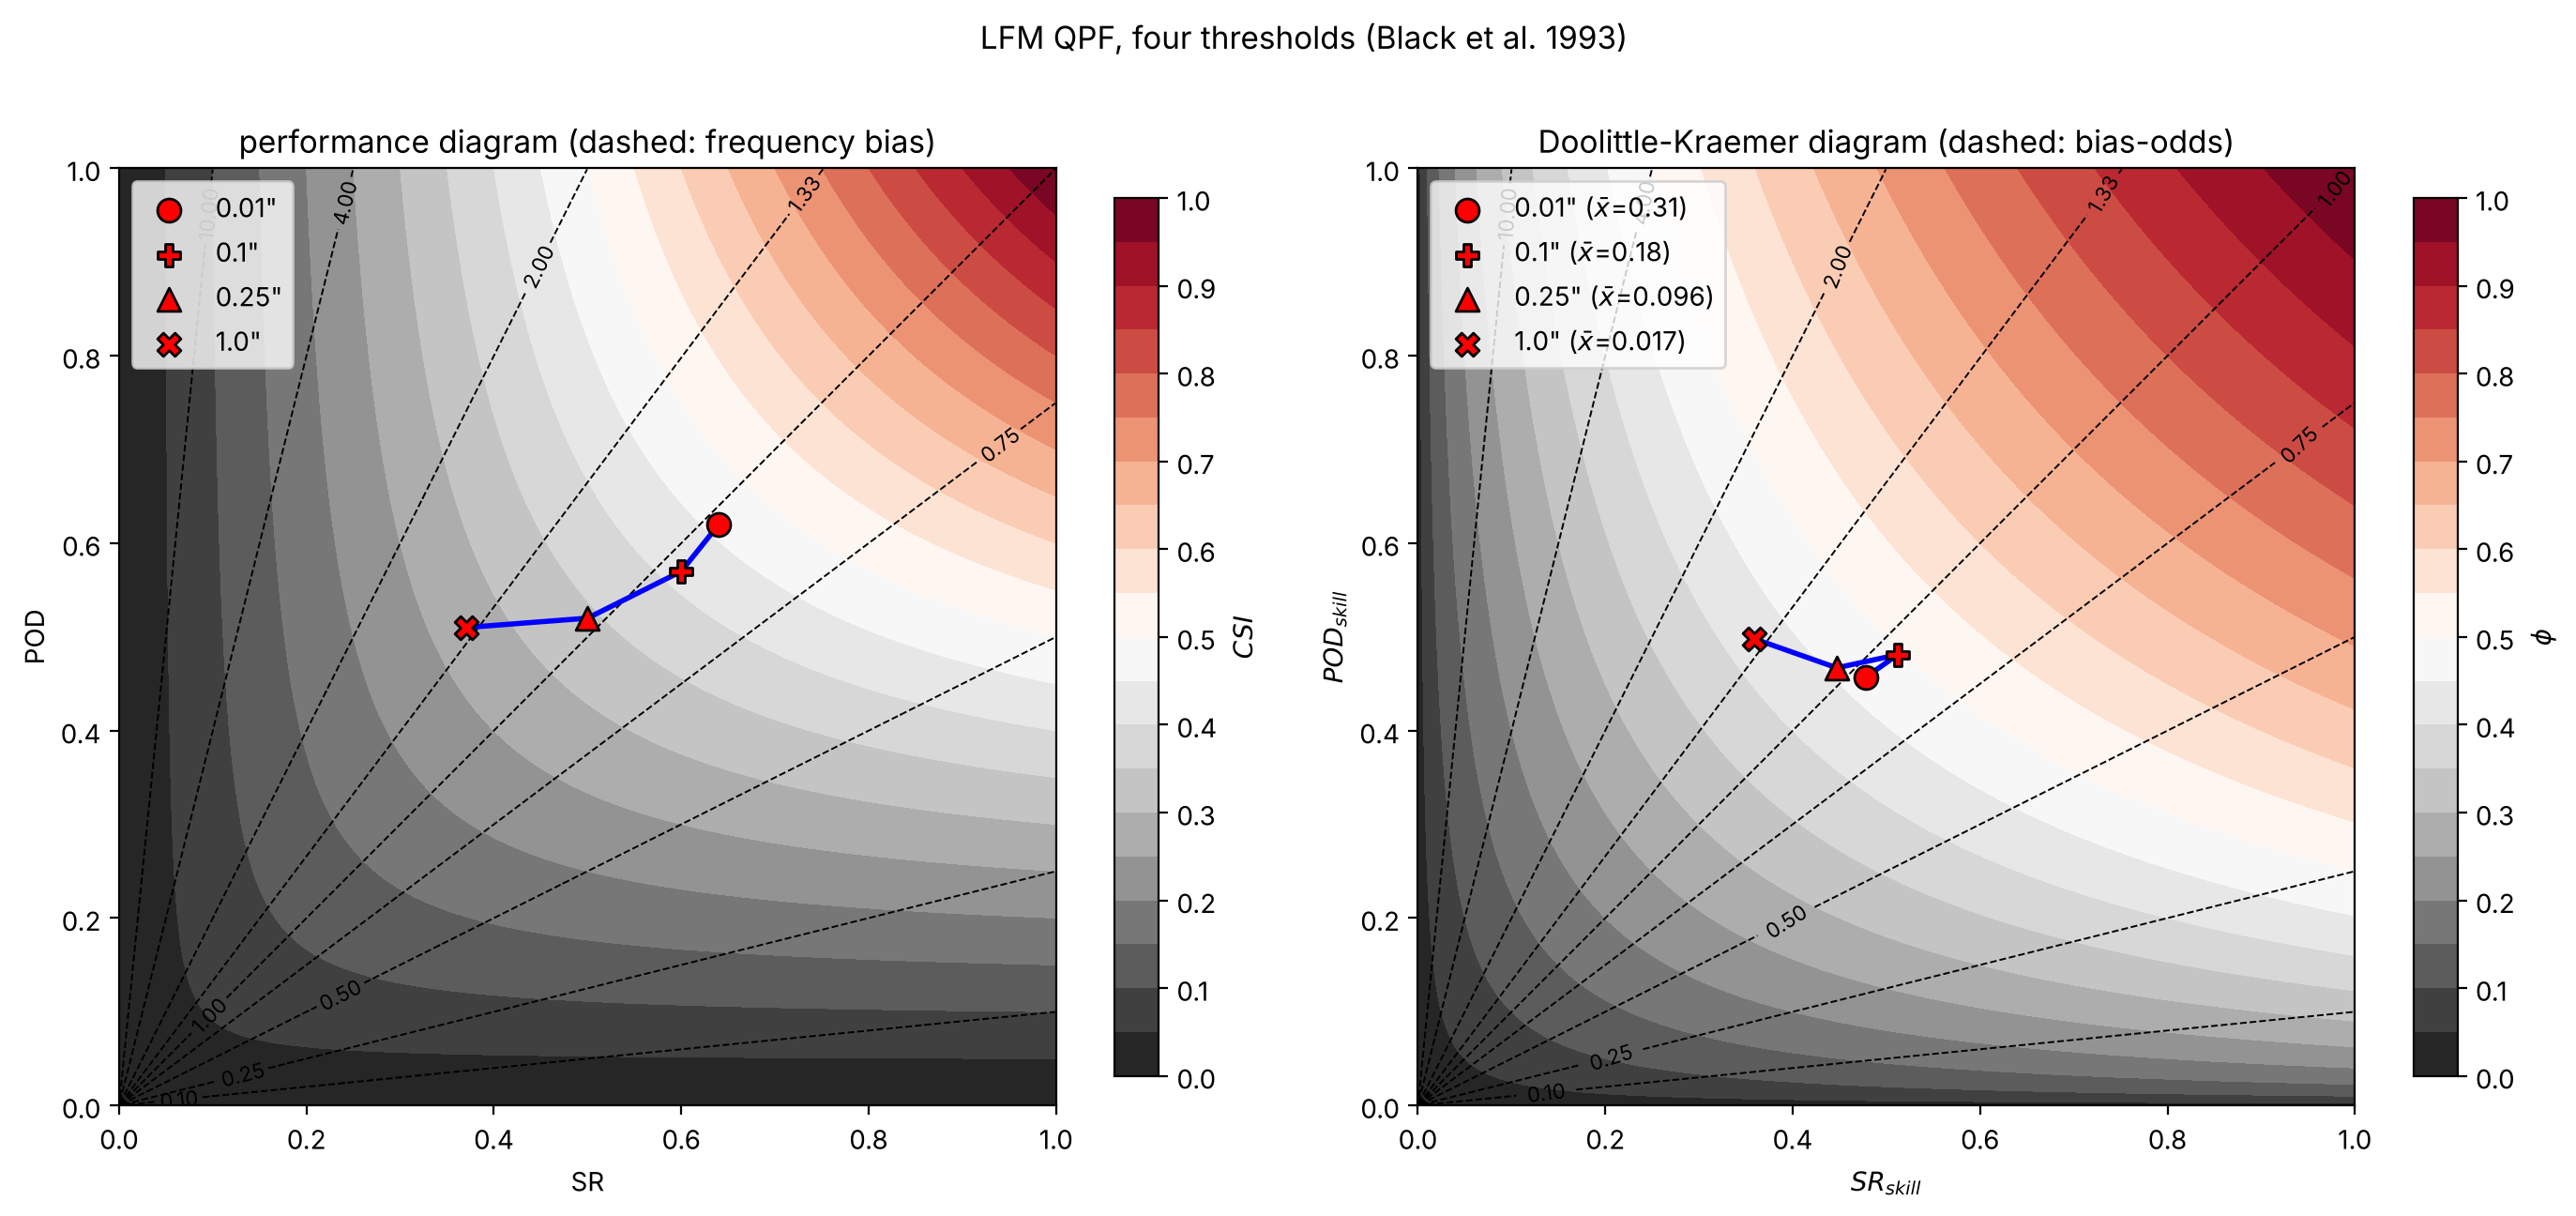

In [17]:
# "classic" performance diagram (as in intro_performance_diagram.ipynb) vs Doolittle-Kraemer diagram, LFM QPF thresholds

fig, axs = plt.subplots(1,2,figsize=(14,6.5))

# left: performance diagram, CSI and bias in the background computed for the 0.01" base rate only
xb_perf=xbar_qpf[0]
pod_y=np.arange(0.001,1.0,0.001)
sr_x=np.arange(0.001,1.0,0.001)
sr_perf,pod_perf=np.meshgrid(sr_x,pod_y)
aa_p=xb_perf*pod_perf
bb_p=xb_perf*(pod_perf/sr_perf-pod_perf)
cc_p=xb_perf*(1.-pod_perf)
dd_p=1.-xb_perf*(pod_perf/sr_perf+1.-pod_perf)
cs0=axs[0].contour(sr_x,pod_y,bias(aa_p,bb_p,cc_p,dd_p),levels=np.array([0.1,0.25,0.5,0.75,1.,1.33,2.,4.,10.]),colors='k',linestyles='dashed',linewidths=0.7)
axs[0].clabel(cs0, cs0.levels, inline=True, fontsize=8)
sc0=axs[0].contourf(sr_x,pod_y,csi(aa_p,bb_p,cc_p,dd_p),levels=np.linspace(0.,1.,21),cmap='RdGy_r')
plt.colorbar(sc0,orientation='vertical',shrink=0.8,label=r'$CSI$',ax=axs[0],ticks=np.linspace(0.,1.,11))
axs[0].plot(sr_qpf,pod_qpf,c='b',lw=2,zorder=5)
for i in np.arange(len(thr1)):
    axs[0].scatter(sr_qpf[i],pod_qpf[i],facecolor='r',edgecolor='k',s=80,marker=markers[i],label=f'{thr1[i]}"',zorder=6)
axs[0].set_xlabel('SR')
axs[0].set_ylabel('POD')
axs[0].set_title('performance diagram (dashed: frequency bias)')

# right: Doolittle-Kraemer diagram, phi in the background (the same for every base rate)
sc1=axs[1].contourf(srs_x,pods_y,np.sqrt(srs_2d*pods_2d),levels=np.linspace(0.,1.,21),cmap='RdGy_r')
plt.colorbar(sc1,orientation='vertical',shrink=0.8,label=r'$\phi$',ax=axs[1],ticks=np.linspace(0.,1.,11))
# bias-odds lines: rays from the origin, POD_skill/SR_skill = constant (the same for every base rate)
cs1=axs[1].contour(srs_x,pods_y,pods_2d/srs_2d,levels=np.array([0.1,0.25,0.5,0.75,1.,1.33,2.,4.,10.]),colors='k',linestyles='dashed',linewidths=0.7)
axs[1].clabel(cs1, cs1.levels, inline=True, fontsize=8)
axs[1].plot(df_qpf.SRskill,df_qpf.PODskill,c='b',lw=2,zorder=5)
for i in np.arange(len(thr1)):
    axs[1].scatter(df_qpf.SRskill[i],df_qpf.PODskill[i],facecolor='r',edgecolor='k',s=80,marker=markers[i],
                   label=f'{thr1[i]}" ('+r'$\bar x$='+f'{xbar_qpf[i]})',zorder=6)
axs[1].set_xlabel(r'$SR_{skill}$')
axs[1].set_ylabel(r'$POD_{skill}$')
axs[1].set_title('Doolittle-Kraemer diagram (dashed: bias-odds)')

for ax in axs:
    ax.set_aspect('equal')
    ax.set_xlim(0.,1.)
    ax.set_ylim(0.,1.)
    ax.legend(loc='upper left')
fig.suptitle('LFM QPF, four thresholds (Black et al. 1993)')
plt.tight_layout()

On the performance diagram, $CSI$ decreases from 0.46 at the 0.01" threshold to 0.27 at the 1" threshold, so the higher thresholds look worse. Relative to random forecasts, the four thresholds are much closer: $\phi$ and $HSS$ are between about 0.42 and 0.50 for all four, and $POD_{skill}$ is between 0.46 and 0.50. The 1" threshold has the lowest $SR_{skill}$ (0.36) and sits above the main diagonal, because it over-forecasts (bias 1.38). The discrimination measure $d'$ increases with threshold (from 1.31 to 2.20), as noted in intro_performance_diagram.ipynb. (These values are computed from the rounded $POD$, $SR$, and $\bar x$ values in the table above.)

### radial lines: frequency bias vs. bias-odds

In both diagrams the dashed lines are rays from the origin, and the angle of a point above or below the main diagonal shows over- or under-forecasting. What the angle measures is different:

- **Performance diagram:** the slope of a ray is the frequency bias, $B=\frac{POD}{SR}=\frac{\bar f}{\bar x}$, the ratio of the forecast and observed event *frequencies*.
- **Doolittle-Kraemer diagram:** the slope of a ray is the bias-odds, $\frac{POD_{skill}}{SR_{skill}}=\frac{\bar f/(1-\bar f)}{\bar x/(1-\bar x)}$, the ratio of the forecast and observed event *odds*.

The two are linked through the base rate, $B=\frac{bias_{odds}}{1+\bar x\,(bias_{odds}-1)}$, so:

- they agree at 1 for every base rate, so the main diagonal means "unbiased" on both diagrams;
- away from 1, bias-odds is always further from 1 than frequency bias, and the gap grows with $\bar x$; for rare events (small $\bar x$) odds and probabilities are nearly equal, so the two are nearly the same;
- frequency bias can be no larger than $1/\bar x$ (the forecast frequency cannot exceed 1), so on a performance diagram rays steeper than $1/\bar x$ cannot be reached, and fewer angles are usable as events become more common; bias-odds runs from 0 to $\infty$ for every base rate, so on the Doolittle-Kraemer diagram every ray can be reached.

On a performance diagram, a ray means the same frequency bias for every point. On a Doolittle-Kraemer diagram, a bias-odds ray corresponds to a different frequency bias for each base rate. For example, bias-odds = 1.33 is a frequency bias of 1.33/(1 + 0.31 × 0.33) = 1.21 at $\bar x$ = 0.31 (the 0.01" threshold), but 1.32 at $\bar x$ = 0.017 (the 1" threshold). For the four QPF thresholds, compare the `bias` and `bias_odds` columns in the table above: they differ by at most 0.014, because three thresholds are nearly unbiased and the one with the largest bias (1", bias 1.38 vs. bias-odds 1.39) has the smallest base rate. The code below checks the conversion formula.

In [18]:
# check: frequency bias from bias-odds and base rate, for the QPF thresholds and for random tables
print('QPF:',np.allclose(df_qpf.bias,df_qpf.bias_odds/(1.+df_qpf.xbar*(df_qpf.bias_odds-1.)),atol=2e-3))
bo_=podskill(a,b,c,d)/srskill(a,b,c,d)
print('random tables:',np.allclose((a+b)/(a+c),bo_/(1.+(a+c)*(bo_-1.))))

QPF: True
random tables: True


## additional score definitions

Additional score calculations are provided as functions in the code block below (same as intro_performance_diagram.ipynb, plus bias-odds). Combined with `table_from_skill()`, any of these can be plotted in the background of a Doolittle-Kraemer diagram for a chosen base rate.

In [19]:
# functions for score calculations from 2x2 contingency table

def pod(a,b,c,d):
    return a/(a+c)

def sr(a,b,c,d):
    return a/(a+b)

def pofd(a,b,c,d):
    return b/(b+d)

def mr(a,b,c,d):
    return c/(c+d)

def csi(a,b,c,d):
    return a/(a+b+c)

def f1(a,b,c,d):
    return 2.*a/(2.*a+b+c)

def tversky(a,b,c,d,gamma):
    return a/(a+gamma*b+(1.-gamma)*c)

def pss(a,b,c,d):
    return (a*d-b*c)/(a+c)/(b+d)

def css(a,b,c,d):
    return (a*d-b*c)/(a+b)/(c+d)

def qyule(a,b,c,d):
    return (a*d-b*c)/(a*d+b*c)

def srskill(a,b,c,d):
    return (a*d-b*c)/(a+b)/(b+d)

def podskill(a,b,c,d):
    return (a*d-b*c)/(a+c)/(c+d)

def hss(a,b,c,d):
    return 2.*(a*d-b*c)/((a+c)*(c+d)+(a+b)*(b+d))

def kappa(a,b,c,d,w):
    return (a*d-b*c)/((1.-w)*(a+c)*(c+d)+w*(a+b)*(b+d))

def dprime(a,b,c,d):
    return norm.ppf(a/(a+c))-norm.ppf(b/(b+d))

def biasodds(a,b,c,d):
    return (a+b)*(b+d)/(a+c)/(c+d)

def oddsr(a,b,c,d):
    return a*d/b/c

def bias(a,b,c,d):
    return (a+b)/(a+c)

def phi(a,b,c,d):
    return (a*d-b*c)/np.sqrt((a+c)*(c+d)*(a+b)*(b+d))

def edi(a,b,c,d):
    return (np.log(b/(b+d))-np.log(a/(a+c)))/(np.log(b/(b+d))+np.log(a/(a+c)))

def sedi(a,b,c,d):
    return (np.log(b/(b+d))-np.log(a/(a+c))-np.log(d/(b+d))+np.log(c/(a+c)))/(np.log(b/(b+d))+np.log(a/(a+c))+np.log(d/(b+d))+np.log(c/(a+c)))

## references

Black, T., D. Deaven, and G. DiMego, 1993: The step-mountain Eta coordinate model: 80 km 'early' version and objective verifications. NWS TPB 412, NOAA, 31 pp. https://s3.us-east-1.amazonaws.com/library.oarcloud.noaa.gov/noaa_documents.lib/NOAA_historic_documents/WB/TPB/1990-1999/TPB_412.pdf

Boyd, K., V. S. Costa, J. Davis, and D. Page, 2012: Unachievable region in precision-recall space and its effect on empirical evaluation. https://arxiv.org/abs/1206.4667

Doolittle, M. H., 1885: The verification of predictions. Bull. Philos. Soc. Washington, 7.

Heidke, P., 1926: Berechnung des Erfolges und der Güte der Windstärkevorhersagen im Sturmwarnungsdienst. Geogr. Ann., 8, https://doi.org/10.1080/20014422.1926.11881138.

Kraemer, H. C., 1988: Assessment of 2 × 2 associations: Generalization of signal-detection methodology. Amer. Stat., 42, https://doi.org/10.1080/00031305.1988.10475520.

Matthews, B. W., 1975: Comparison of the predicted and observed secondary structure of T4 phage lysozyme. Biochim. Biophys. Acta, 405, 442–451.

Richardson, D. S., 2000: Skill and relative economic value of the ECMWF ensemble prediction system. Quart. J. Roy. Meteor. Soc., 126, 649–667.

Roebber, P. J., 2009: Visualizing multiple measures of forecast quality. Wea. Forecasting, 24, https://doi.org/10.1175/2008WAF2222159.1.

Schaefer, J. T., 1990: The critical success index as an indicator of warning skill. Wea. Forecasting, 5, https://doi.org/10.1175/1520-0434(1990)005<0570:TCSIAA>2.0.CO;2.

Wandishin, M. S., and H. E. Brooks, 2002: On the relationship between Clayton's skill score and expected value for forecasts of binary events. Meteor. Appl., 9, https://doi.org/10.1017/S1350482702004085.

Yule, G. U., 1912: On the methods of measuring association between two attributes. J. Roy. Stat. Soc., 75.